# Clasificación de afinidad temática de contratos SECOP II con TF-IDF y SVM lineal
### Proyecto SEIA · Aprendizaje supervisado (clasificación de texto / NLP)

**Contexto.** La documentación de SEIA (`seia-app/src/app/documentacion/page.tsx`, Sección 3 "Materia Machine Learning") describe un modelo de clasificación NLP, entrenado en un notebook externo, que analiza el **objeto contractual** de cada proceso de SECOP II para predecir su **relevancia frente al portafolio de MGD Bitforge S.A.S.**: gestión documental, archivística y tecnología (SGDEA). Este notebook construye ese modelo.

**Problema de clasificación binaria.**
- **Variable de entrada (X):** el texto libre `objeto_del_contrato`, vectorizado con TF-IDF.
- **Variable objetivo (y):** `afin_portafolio`. Vale 1 si el contrato pertenece a los códigos UNSPSC de **tecnologías de la información** o de **gestión documental**, y 0 en caso contrario.

**¿Por qué es útil?** Hoy SEIA filtra por códigos UNSPSC, palabras clave y modalidades (`parametros_busqueda`). Pero las entidades a veces asignan códigos genéricos: por ejemplo, un desarrollo de software registrado como "servicios de personal". Un clasificador que **lee el texto** puede marcar como relevantes procesos que un filtro por código dejaría pasar, y ordenar los resultados por afinidad.

**Modelo:** SVM lineal (`LinearSVC`). **No se usa Regresión Lineal**, que el enunciado prohíbe; la justificación del modelo está en la sección 8.

| Sección | Contenido |
|---|---|
| 1 | Configuración del entorno |
| 2 | Carga de datos desde la API de datos.gov.co |
| 3 | Definición de la variable objetivo |
| 4 | Exploración de los datos |
| 5 | Preparación: nulos, códigos inválidos, limpieza de texto, duplicados |
| 6 | División en entrenamiento y prueba |
| 7 | Vectorización TF-IDF |
| 8 | Selección y justificación del modelo |
| 9 | Ajuste de hiperparámetros |
| 10 | Evaluación en el conjunto de prueba |
| 11 | Interpretación del modelo y análisis de errores |
| 12 | Uso del modelo en SEIA |
| 13 | Interpretación de resultados y de las métricas |
| 14 | Limitaciones y posibles errores |
| 15 | Conclusiones |

## 1. Configuración del entorno

In [1]:
import io
import os
import re
import time
import unicodedata
from collections import Counter

import joblib
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, make_scorer,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, roc_auc_score, roc_curve)

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.3.3 | numpy 2.0.2 | scikit-learn 1.6.1


## 2. Carga de datos desde la API de datos.gov.co
**Fuente:** [SECOP II – Contratos Electrónicos](https://www.datos.gov.co/Gastos-Gubernamentales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h) (`jbjy-vk9h`), el mismo endpoint que consume `seia-services`.

**Subconjunto.** Contratos firmados en **2024**, en una **muestra sistemática del 30 %**: los `id_contrato` que terminan en 1, 4 o 7. Son ≈ 267.000 registros. El último dígito del identificador no tiene relación con el contenido del contrato, así que la muestra cubre todo el año y todas las entidades.

**Privacidad.** Solo se descargan el texto del objeto, el código UNSPSC y algunas columnas descriptivas del contrato. Ningún dato personal de los contratistas.

In [2]:
URL_SECOP = 'https://www.datos.gov.co/resource/jbjy-vk9h.csv'
FILTRO_2024_MUESTRA = (
    "fecha_de_firma between '2024-01-01T00:00:00' and '2024-12-31T23:59:59' "
    "AND (id_contrato like '%1' OR id_contrato like '%4' OR id_contrato like '%7')"
)
COLUMNAS = ['id_contrato', 'codigo_de_categoria_principal', 'objeto_del_contrato',
            'tipo_de_contrato', 'modalidad_de_contratacion', 'sector', 'valor_del_contrato']
ARCHIVO_CACHE = os.path.join('datos_secop', 'contratos_2024_muestra_texto.parquet')


def descargar_secop(columnas, filtro, archivo, tam_pagina=50_000, reintentos=5):
    """Descarga por páginas desde la API SODA de datos.gov.co y guarda una copia local."""
    if os.path.exists(archivo):
        print('Cargando copia local:', archivo)
        return pd.read_parquet(archivo)
    os.makedirs(os.path.dirname(archivo), exist_ok=True)
    paginas, offset, inicio = [], 0, time.time()
    while True:
        params = {'$select': ','.join(columnas), '$where': filtro, '$order': ':id',
                  '$limit': tam_pagina, '$offset': offset}
        for intento in range(1, reintentos + 1):
            try:
                respuesta = requests.get(URL_SECOP, params=params, timeout=300)
                respuesta.raise_for_status()
                break
            except requests.RequestException as error:
                if intento == reintentos:
                    raise
                print(f'  reintento {intento} por error: {error}')
                time.sleep(10 * intento)
        pagina = pd.read_csv(io.StringIO(respuesta.text), dtype=str)
        paginas.append(pagina)
        offset += len(pagina)
        print(f'  {offset:>9,} registros descargados ({time.time() - inicio:,.0f} s)')
        if len(pagina) < tam_pagina:
            break
    datos = pd.concat(paginas, ignore_index=True)
    datos.to_parquet(archivo, index=False)
    return datos


df_raw = descargar_secop(COLUMNAS, FILTRO_2024_MUESTRA, ARCHIVO_CACHE)
print(f'\nDatos: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} columnas')
df_raw.head()

     50,000 registros descargados (17 s)


    100,000 registros descargados (28 s)


    150,000 registros descargados (55 s)


    200,000 registros descargados (61 s)


    250,000 registros descargados (92 s)


    267,158 registros descargados (100 s)



Datos: 267,158 registros x 7 columnas


,id_contrato,codigo_de_categoria_principal,objeto_del_contrato,tipo_de_contrato,modalidad_de_contratacion,sector,valor_del_contrato
0,CO1.PCCNTR.7072264,V1.80111701,PRESTACIÓN DE SERVICIOS DE APOYO A LA GESTIÓN EN LA SOCIALIZACIÓN; VERIFICACIÓN Y CUMPLIMIENTO DEL SISTEMA DE SEGURIDAD; ORDEN PÚBLICO Y CONVIVENCIA CIUDADA...,Prestación de servicios,Contratación directa,No aplica/No pertenece,2106000
1,CO1.PCCNTR.6984441,V1.80111600,PRESTAR SERVICIOS COMO PROFESIONAL UNIVERSITARIO EN MEDICINA VETERINARIA PARA DESARROLLAR ACTIVIDADES EN EL PLAN DE SALUD PUBLICA DE INTERVENCIONES COLECTIV...,Prestación de servicios,Contratación régimen especial,Salud y Protección Social,7996272
2,CO1.PCCNTR.7069564,V1.80111600,PRESTAR SERVICIOS PROFESIONALES EN LA UNIDAD ADMINISTRATIVA ESPECIAL DE SERVICIOS PUBLICOS DEL DISTRITO DE SANTIAGO DE CALI.,Prestación de servicios,Contratación directa,No aplica/No pertenece,8876000
3,CO1.PCCNTR.7128497,V1.80111700,161-023200_0203 Prestar servicios profesionales especializados en la Dirección de Aseguramiento y Garantía del Derecho a la Salud - Subdirección de Garantía...,Prestación de servicios,Contratación directa,Salud y Protección Social,45818765
4,CO1.PCCNTR.6442841,V1.80131503,CONTRATAR EN ARRENDAMIENTO UN LOTE EN EL SECTOR DE COSTA VERDE EN EL MUNICIPIO DE CIÉNAGA; DONDE SE PUEDA OPERAR UN EQUIPO MUESTREADOR MANUAL DE ALTO VOLUME...,Arrendamiento de inmuebles,Contratación directa,Ambiente y Desarrollo Sostenible,12000000


## 3. Definición de la variable objetivo
El portafolio de referencia es **gestión documental, archivística y tecnología (SGDEA)**. Se traduce a códigos del clasificador UNSPSC que usa Colombia Compra Eficiente. El formato es `V1.SSFFCCPP`: segmento, familia, clase y producto.

| Código UNSPSC | Nivel | Contenido | Parte del portafolio |
|---|---|---|---|
| `43……` | Segmento 43 | Tecnologías de la información y telecomunicaciones: equipos, componentes, redes y **software** | Tecnología / plataforma SGDEA |
| `8111….` | Familia 8111 | **Servicios informáticos**: desarrollo, ingeniería de software, soporte | Tecnología |
| `8116….` | Familia 8116 | **Entrega de servicios de TI**: nube, hosting, mesa de servicios | Tecnología |
| `80161506` | Producto | Servicios de **archivo** de datos | Archivística |
| `78131804` | Producto | **Almacenamiento y custodia de documentos** | Gestión documental |

`afin_portafolio = 1` si el código del contrato cae en alguno de estos grupos; si no, vale 0. La etiqueta sale de un **campo oficial del contrato**, distinto del texto que el modelo recibe como entrada, así que no hay fuga de información: el código no aparece en el texto que se vectoriza.

In [3]:
codigo = df_raw['codigo_de_categoria_principal'].str.replace('V1.', '', regex=False)
df_raw['codigo_unspsc'] = codigo
df_raw['codigo_valido'] = codigo.str.fullmatch(r'\d{8}')

segmento, familia = codigo.str[:2], codigo.str[:4]
GRUPOS_PORTAFOLIO = {
    'Segmento 43 · TIC (equipos y software)': segmento.eq('43'),
    'Familia 8111 · Servicios informáticos': familia.eq('8111'),
    'Familia 8116 · Entrega de servicios de TI': familia.eq('8116'),
    '80161506 · Archivo de datos': codigo.eq('80161506'),
    '78131804 · Custodia de documentos': codigo.eq('78131804'),
}
df_raw['afin_portafolio'] = np.logical_or.reduce(list(GRUPOS_PORTAFOLIO.values())).astype(int)
df_raw['grupo_portafolio'] = np.select(list(GRUPOS_PORTAFOLIO.values()), list(GRUPOS_PORTAFOLIO.keys()), default='No afín')

print(df_raw['grupo_portafolio'].value_counts().to_string())
print(f"\nTasa de contratos afines: {df_raw['afin_portafolio'].mean():.2%}")

grupo_portafolio
No afín                                      262932
Familia 8111 · Servicios informáticos          2434
Segmento 43 · TIC (equipos y software)         1411
80161506 · Archivo de datos                     220
Familia 8116 · Entrega de servicios de TI       130
78131804 · Custodia de documentos                31

Tasa de contratos afines: 1.58%


## 4. Exploración de los datos
### 4.1 Tipos, nulos y valores inválidos

In [4]:
df_raw.info(show_counts=True)
texto = df_raw['objeto_del_contrato'].fillna('')
resumen = pd.Series({
    'Nulos en objeto_del_contrato': df_raw['objeto_del_contrato'].isna().sum(),
    'Nulos en codigo_de_categoria_principal': df_raw['codigo_de_categoria_principal'].isna().sum(),
    'Código UNSPSC no válido (p. ej. UNSPECIFIED)': (~df_raw['codigo_valido']).sum(),
    "Objeto con menos de 15 caracteres (p. ej. 'No definido')": (texto.str.len() < 15).sum(),
    'Textos de objeto repetidos exactamente': texto.duplicated().sum(),
}, name='registros')
resumen.to_frame().assign(porcentaje=lambda t: (t['registros'] / len(df_raw) * 100).round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267158 entries, 0 to 267157
Data columns (total 11 columns):
 #   Column                         Non-Null Count   Dtype 
---  ------                         --------------   ----- 
 0   id_contrato                    267158 non-null  object
 1   codigo_de_categoria_principal  267158 non-null  object
 2   objeto_del_contrato            267158 non-null  object
 3   tipo_de_contrato               267158 non-null  object
 4   modalidad_de_contratacion      267158 non-null  object
 5   sector                         267158 non-null  object
 6   valor_del_contrato             267158 non-null  object
 7   codigo_unspsc                  267158 non-null  object
 8   codigo_valido                  267158 non-null  bool  
 9   afin_portafolio                267158 non-null  int64 
 10  grupo_portafolio               267158 non-null  object
dtypes: bool(1), int64(1), object(9)
memory usage: 20.6+ MB


,registros,porcentaje
Nulos en objeto_del_contrato,0,0.00
Nulos en codigo_de_categoria_principal,0,0.00
Código UNSPSC no válido (p. ej. UNSPECIFIED),3996,1.50
Objeto con menos de 15 caracteres (p. ej. 'No definido'),429,0.16
Textos de objeto repetidos exactamente,71083,26.61


### 4.2 Longitud de los textos

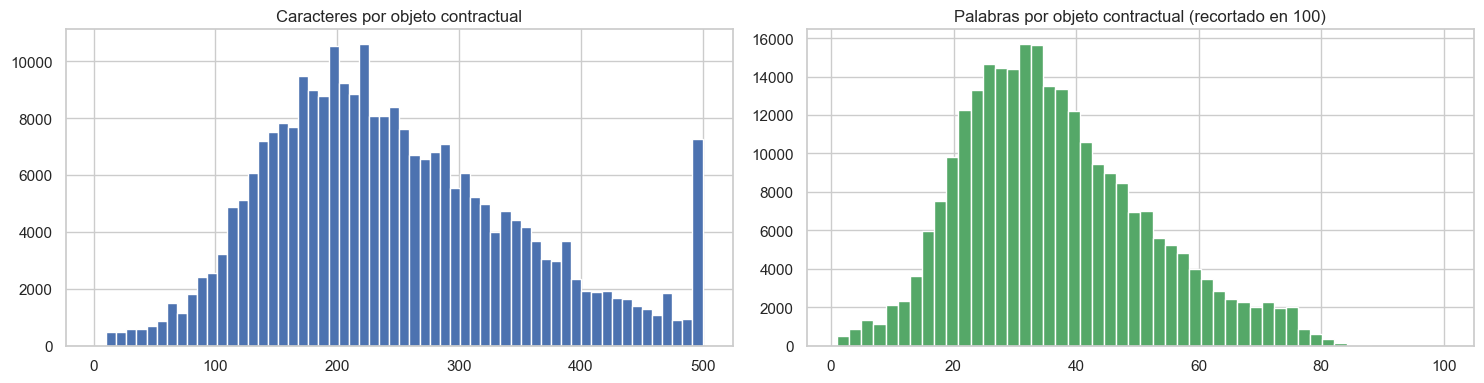

count    267158.0
mean        246.2
std         102.9
min           2.0
25%         171.0
50%         231.0
75%         310.0
max         500.0


In [5]:
longitud = texto.str.len()
palabras = texto.str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
longitud.plot.hist(bins=60, ax=axes[0], color='#4C72B0')
axes[0].set(title='Caracteres por objeto contractual', ylabel='')
palabras.clip(upper=100).plot.hist(bins=50, ax=axes[1], color='#55A868')
axes[1].set(title='Palabras por objeto contractual (recortado en 100)', ylabel='')
plt.tight_layout()
plt.show()
print(longitud.describe().round(1).to_string())

El campo tiene un máximo de unos **500 caracteres**: la API lo recorta. La mayoría de los objetos tiene entre 25 y 50 palabras, una longitud suficiente para un modelo de bolsa de palabras.

### 4.3 Desbalance de clases

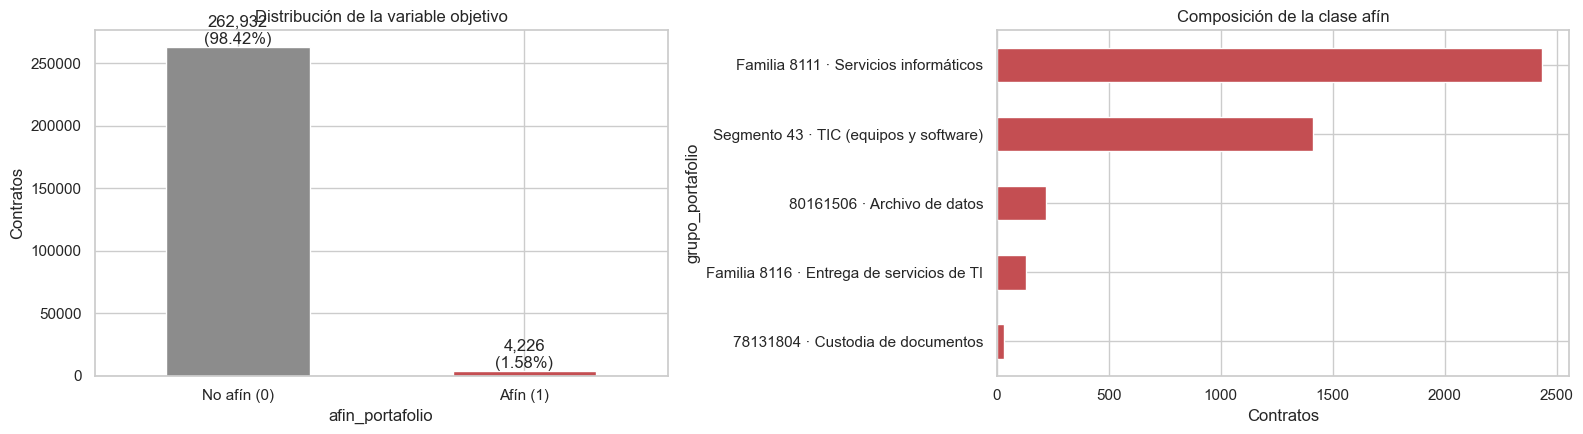

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
conteo = df_raw['afin_portafolio'].value_counts().rename({0: 'No afín (0)', 1: 'Afín (1)'})
conteo.plot.bar(ax=axes[0], color=['#8C8C8C', '#C44E52'])
axes[0].set(title='Distribución de la variable objetivo', ylabel='Contratos')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(conteo):
    axes[0].text(i, v, f'{v:,}\n({v / conteo.sum():.2%})', ha='center', va='bottom')
df_raw.loc[df_raw['afin_portafolio'] == 1, 'grupo_portafolio'].value_counts().plot.barh(ax=axes[1], color='#C44E52')
axes[1].set(title='Composición de la clase afín', xlabel='Contratos')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

El problema está **muy desbalanceado**: solo alrededor del 1,6 % de los contratos es afín. Esto tiene dos consecuencias para el resto del trabajo:
1. La **accuracy por sí sola engaña**: un modelo que siempre responda "no afín" acertaría más del 98 %. Por eso las métricas que importan son la **precisión, el recall y el F1 de la clase afín**.
2. La división en entrenamiento y prueba tiene que ser **estratificada**, para que ambos conjuntos conserven la misma proporción de afines.

### 4.4 Variables categóricas descriptivas por clase

In [7]:
for col in ['tipo_de_contrato', 'modalidad_de_contratacion', 'sector']:
    tabla = (pd.crosstab(df_raw[col], df_raw['afin_portafolio'], normalize='columns') * 100).round(2)
    tabla.columns = ['% en No afín', '% en Afín']
    print(f'=== {col} ===')
    display(tabla.sort_values('% en Afín', ascending=False).head(6))

=== tipo_de_contrato ===


,% en No afín,% en Afín
tipo_de_contrato,,
Prestación de servicios,86.09,60.86
Compraventa,1.40,17.82
Otro,3.96,9.91
Suministros,2.34,6.08
Decreto 092 de 2017,3.83,4.38
Comodato,0.16,0.64


=== modalidad_de_contratacion ===


,% en No afín,% en Afín
modalidad_de_contratacion,,
Contratación directa,75.72,45.72
Mínima cuantía,4.83,21.18
Contratación régimen especial,15.50,14.77
Selección abreviada subasta inversa,0.70,8.71
Contratación Directa (con ofertas),1.03,5.68
Contratación régimen especial (con ofertas),0.81,2.93


=== sector ===


,% en No afín,% en Afín
sector,,
Servicio Público,25.54,19.36
No aplica/No pertenece,16.00,14.58
Salud y Protección Social,15.49,10.06
Educación Nacional,5.39,9.11
defensa,2.90,5.54
Industria,1.05,4.87


Los contratos afines son proporcionalmente **más de compraventa, suministro y de empresas** que el promedio, que está dominado por la prestación de servicios de personas naturales. Estas variables categóricas **no se usan como entrada** del modelo, porque se quiere un clasificador que dependa solo del texto. Así funciona igual con procesos nuevos que todavía no tienen todos los campos completos. Se usan para entender los datos.

### 4.5 Ejemplos y vocabulario de cada clase

In [8]:
print('Ejemplos de contratos AFINES:')
for t in df_raw.loc[df_raw['afin_portafolio'] == 1, 'objeto_del_contrato'].sample(6, random_state=SEED):
    print('  •', t[:180])
print('\nEjemplos de contratos NO AFINES:')
for t in df_raw.loc[df_raw['afin_portafolio'] == 0, 'objeto_del_contrato'].sample(6, random_state=SEED):
    print('  •', t[:180])

Ejemplos de contratos AFINES:
  • Prestar los servicios para la ejecución de actividades de soporte técnico de nivel 3 a las plataformas de aprendizaje virtual Moodle implementadas y en uso; para garantizar el func
  • FASE 1:ACTUALIZACIÓN TÉCNICA Y EVOLUCIÓN FUNCIONAL DEL ERP SAP DE LA GOBERNACIÓN DE CALDAS DE ACUERDO CON LAS NECESIDADES DE LA ENTIDAD PARA EL CUMPLIMIENTO DE SUS FUNCIONES DENTRO
  • PRESTACIÓN DE SERVICIOS TÉCNICOS PARA EL MANTENIMIENTO PREVENTIVO Y CORRECTIVO DE LOS EQUIPOS DE LA ESP.
  • 14-03-8100-ADQUIRIR BOLSA DE PLUGINS DE ACCESIBILIDAD PARA LOS SITIOS WEB DEL JARDÍN BOTÁNICO DE BOGOTÁ
  • Adquisición del licenciamiento de antivirus y office para los quipos de cómputo de la Personería municipal de Sabaneta
  • PRESTACIÓN DE SERVICIOS PROFESIONALES PARA EL ANÁLISIS; DESARROLLO; AJUSTES; MANTENIMIENTO; DOCUMENTACIÓN; PRUEBAS; ASESORÍA Y ACOMPAÑAMIENTO DEL SISTEMA DE INFORMACIÓN COMERCIAL P

Ejemplos de contratos NO AFINES:
  • PRESTAR SERVICIOS PROFESIONALES DE AS

## 5. Preparación de los datos
### 5.1 Nulos y códigos inválidos
- Se eliminan los registros con código UNSPSC no válido (`UNSPECIFIED` u otro formato): **sin código no hay etiqueta**, y no se puede imputar la variable objetivo sin inventarla.
- Los objetos vacíos o con menos de 15 caracteres (`No definido`, `N/A`) se eliminan, porque **no contienen información** que el modelo pueda leer.

In [9]:
df = df_raw[df_raw['codigo_valido']].copy()
print(f'Tras quitar códigos inválidos: {len(df):,}')

Tras quitar códigos inválidos: 263,162


### 5.2 Limpieza y normalización del texto
1. Convertir a minúsculas y **quitar tildes** (`gestión` y `gestion` deben ser la misma palabra).
2. Quitar puntuación y símbolos.
3. Quitar **números aislados**: años, números de contrato y cantidades. Son ruido para la temática.
4. Unificar espacios.

Las *stopwords* del español (artículos, preposiciones…) se eliminan después, en el vectorizador.

In [10]:
def limpiar_texto(texto):
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    texto = ''.join(ch for ch in texto if not unicodedata.combining(ch))
    texto = re.sub(r'[^a-z0-9 ]', ' ', texto)
    texto = re.sub(r'\b\d+\b', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()


df['texto_limpio'] = df['objeto_del_contrato'].fillna('').map(limpiar_texto)
antes = len(df)
df = df[df['texto_limpio'].str.len() >= 15]
print(f'Textos vacíos o demasiado cortos eliminados: {antes - len(df):,} | Registros: {len(df):,}')
print('\nEjemplo de limpieza:')
ejemplo = df.iloc[0]
print('  original:', ejemplo['objeto_del_contrato'][:160])
print('  limpio:  ', ejemplo['texto_limpio'][:160])

Textos vacíos o demasiado cortos eliminados: 439 | Registros: 262,723

Ejemplo de limpieza:
  original: PRESTACIÓN DE SERVICIOS DE APOYO A LA GESTIÓN EN LA SOCIALIZACIÓN; VERIFICACIÓN Y CUMPLIMIENTO DEL SISTEMA DE SEGURIDAD; ORDEN PÚBLICO Y CONVIVENCIA CIUDADANA A
  limpio:   prestacion de servicios de apoyo a la gestion en la socializacion verificacion y cumplimiento del sistema de seguridad orden publico y convivencia ciudadana a n


### 5.3 Tratamiento de duplicados
En SECOP II es muy común que **una entidad firme muchos contratos con exactamente el mismo objeto**; por ejemplo, decenas de "prestación de servicios de apoyo a la gestión" iguales. Si esos duplicados quedan, el mismo texto puede caer a la vez en entrenamiento y en prueba, y el modelo sería evaluado con ejemplos que ya "memorizó". Eso **inflaría las métricas** (fuga de datos).

Tratamiento:
1. Los textos limpios idénticos **con la misma etiqueta** se dejan en un solo registro.
2. Los textos idénticos **con etiquetas distintas** (el mismo objeto codificado una vez como afín y otra como no afín) son contradictorios. Se eliminan por completo para no enseñarle al modelo información inconsistente.

In [11]:
antes = len(df)
etiquetas_por_texto = df.groupby('texto_limpio')['afin_portafolio'].nunique()
textos_conflicto = etiquetas_por_texto[etiquetas_por_texto > 1].index
df = df[~df['texto_limpio'].isin(textos_conflicto)]
despues_conflicto = len(df)
df = df.drop_duplicates(subset=['texto_limpio', 'afin_portafolio']).reset_index(drop=True)

print(f'Textos con etiquetas contradictorias: {len(textos_conflicto):,} '
      f'({antes - despues_conflicto:,} registros eliminados)')
print(f'Duplicados eliminados: {despues_conflicto - len(df):,}')
print(f'\nDATASET FINAL: {len(df):,} contratos únicos | afines: {df["afin_portafolio"].sum():,} '
      f'({df["afin_portafolio"].mean():.2%})')

Textos con etiquetas contradictorias: 62 (453 registros eliminados)
Duplicados eliminados: 96,173

DATASET FINAL: 166,097 contratos únicos | afines: 3,895 (2.35%)


### 5.4 Palabras más frecuentes por clase (tras la limpieza)

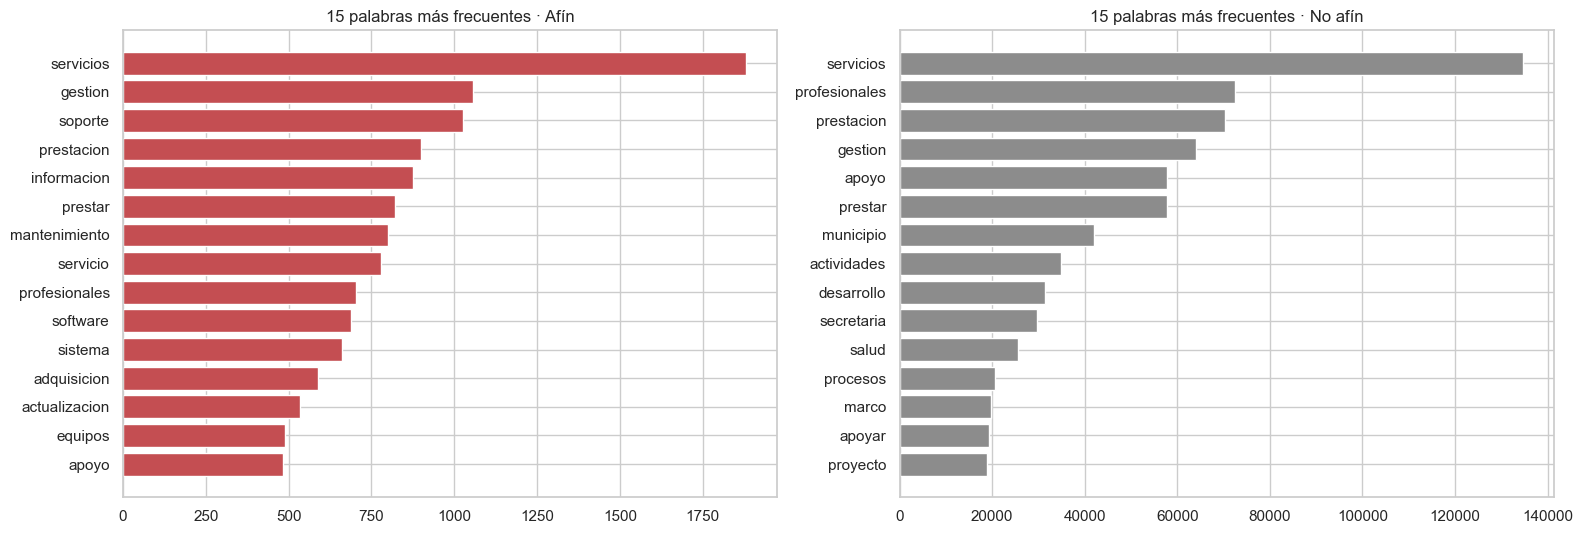

In [12]:
STOPWORDS_ES = '''a al algo algunas algunos ante antes como con contra cual cuando de del desde donde durante e el
ella ellas ellos en entre era es esa esas ese eso esos esta estas este esto estos fue fueron ha han hasta hay la las le
les lo los mas me mi mis mucho muy ni no nos o otra otras otro otros para pero por que quien se sea segun ser si sin
sobre su sus tambien tanto te tiene tienen todo todos tu tus un una uno unos y ya'''.split()


def palabras_frecuentes(textos, n=15):
    contador = Counter(p for t in textos for p in t.split() if p not in STOPWORDS_ES and len(p) > 2)
    return pd.DataFrame(contador.most_common(n), columns=['palabra', 'frecuencia'])


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, clase, color, titulo in [(axes[0], 1, '#C44E52', 'Afín'), (axes[1], 0, '#8C8C8C', 'No afín')]:
    top = palabras_frecuentes(df.loc[df['afin_portafolio'] == clase, 'texto_limpio'])
    ax.barh(top['palabra'][::-1], top['frecuencia'][::-1], color=color)
    ax.set_title(f'15 palabras más frecuentes · {titulo}')
plt.tight_layout()
plt.show()

## 6. División en entrenamiento y prueba
- **80 % entrenamiento / 20 % prueba**, con `stratify=y` para conservar la proporción de afines en ambos conjuntos.
- La división se hace **antes** de vectorizar. Así el vocabulario y los pesos IDF se aprenden solo con el entrenamiento, y la prueba simula textos nunca vistos.

In [13]:
X_texto = df['texto_limpio']
y = df['afin_portafolio']
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X_texto, y, test_size=0.20, stratify=y, random_state=SEED)

pd.DataFrame({
    'registros': [len(y_train), len(y_test)],
    'afines': [y_train.sum(), y_test.sum()],
    '% afines': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento', 'Prueba']).round(3)

,registros,afines,% afines
Entrenamiento,132877,3116,2.345
Prueba,33220,779,2.345


## 7. Vectorización TF-IDF
Cada texto se convierte en un vector disperso. Cada posición corresponde a una palabra o a un par de palabras consecutivas (bigrama), y su peso es:

`tf-idf(t, d) = (1 + log tf) × idf(t)`

- **tf** es la frecuencia del término en el documento. Con `sublinear_tf` se aplica un logaritmo para que repetir una palabra no domine el peso.
- **idf** penaliza los términos que aparecen en casi todos los documentos, como "prestación" o "servicios".

| Parámetro | Valor | Razón |
|---|---|---|
| `ngram_range` | (1, 2) | Los bigramas capturan expresiones como "gestion documental", "mesa ayuda" o "licencias software" |
| `min_df` | 2 | Descarta los términos que aparecen en un solo documento (errores de digitación, nombres propios) |
| `max_df` | 0,9 | Descarta los términos presentes en más del 90 % de los documentos |
| `stop_words` | lista en español | Elimina palabras sin contenido temático |
| `sublinear_tf` | True | Suaviza el efecto de las repeticiones |

In [14]:
vectorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True,
                               stop_words=STOPWORDS_ES)
inicio = time.time()
X_train = vectorizador.fit_transform(X_train_txt)
X_test = vectorizador.transform(X_test_txt)
print(f'Vectorización: {time.time() - inicio:.1f} s')
print(f'Matriz de entrenamiento: {X_train.shape[0]:,} documentos x {X_train.shape[1]:,} términos')
print(f'Matriz de prueba:        {X_test.shape[0]:,} documentos x {X_test.shape[1]:,} términos')
print(f'Densidad (fracción de celdas no nulas): {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.5%}')

Vectorización: 2.5 s
Matriz de entrenamiento: 132,877 documentos x 186,852 términos
Matriz de prueba:        33,220 documentos x 186,852 términos
Densidad (fracción de celdas no nulas): 0.01866%


## 8. Selección y justificación del modelo
Se comparan, con **validación cruzada estratificada de 3 particiones sobre el conjunto de entrenamiento** (sin tocar la prueba), un modelo de referencia y dos candidatos:

| Modelo | Por qué se evalúa |
|---|---|
| `DummyClassifier` (clase mayoritaria) | Línea base. Muestra cuánto vale "no aprender nada" y confirma que la accuracy engaña |
| `ComplementNB` (Naive Bayes) | Clásico para texto: muy rápido y pensado para clases desbalanceadas |
| `LinearSVC` (SVM lineal) | Estado del arte clásico para clasificación de texto con TF-IDF |

**¿Por qué una SVM lineal?**
1. **Alta dimensionalidad dispersa.** Con más de 100.000 términos y pocas palabras activas por documento, las clases suelen ser casi separables por un hiperplano, que es exactamente lo que busca una SVM.
2. **Margen máximo y regularización.** La SVM busca el hiperplano con mayor margen entre las clases, y el parámetro `C` controla la regularización. Eso la hace robusta frente al sobreajuste aunque haya más variables que documentos afines.
3. **Eficiencia.** `LinearSVC` (liblinear) entrena con más de 100.000 documentos en segundos.
4. **Interpretabilidad.** Cada término tiene un coeficiente. Los positivos empujan hacia "afín" y los negativos hacia "no afín", así que se puede explicar cada predicción.
5. **Manejo del desbalance.** `class_weight='balanced'` aumenta el costo de equivocarse con la clase minoritaria.

**Sobre la restricción del enunciado:** la Regresión Lineal no se usa. Además, no sirve para clasificar, porque predice valores continuos sin límites en lugar de clases. La SVM es un clasificador de margen máximo con pérdida *hinge*, un modelo distinto.

In [15]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
metricas_cv = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
}
candidatos = {
    'Dummy (clase mayoritaria)': DummyClassifier(strategy='most_frequent'),
    'Complement Naive Bayes': ComplementNB(alpha=0.3),
    'LinearSVC (C=1)': LinearSVC(C=1.0, max_iter=10_000, random_state=SEED),
}
filas = []
for nombre, modelo_c in candidatos.items():
    inicio = time.time()
    res = cross_validate(modelo_c, X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=-1)
    filas.append({'modelo': nombre, **{m: res[f'test_{m}'].mean() for m in metricas_cv},
                  'tiempo_s': time.time() - inicio})
comparacion = pd.DataFrame(filas).set_index('modelo')
comparacion.round(4)

,accuracy,precision,recall,f1,tiempo_s
modelo,,,,,
Dummy (clase mayoritaria),0.9765,0.0000,0.0000,0.0000,1.3735
Complement Naive Bayes,0.9680,0.3896,0.6377,0.4834,0.8049
LinearSVC (C=1),0.9859,0.8214,0.5071,0.6270,0.4982


### Resultado de la comparación
- **Dummy**: accuracy ≈ 0,977 con **F1 = 0**. Es la "paradoja de la accuracy": sin aprender nada se acierta casi el 98 %, porque basta con responder siempre "no afín". Por eso la accuracy no puede ser el criterio de selección.
- **Complement Naive Bayes**: recall ≈ 0,64, pero con precisión baja (≈ 0,39), lo que da F1 ≈ 0,48. Detecta muchos afines a costa de muchos falsos positivos.
- **LinearSVC**: tiene el **mejor F1 (≈ 0,63)** con una precisión alta (≈ 0,82). Con los pesos por defecto prioriza la precisión y pierde recall (≈ 0,51), así que en la sección 9 se ajusta `class_weight` para equilibrar.

**Modelo seleccionado: LinearSVC.**

## 9. Ajuste de hiperparámetros
`GridSearchCV` con validación cruzada estratificada de 3 particiones sobre el entrenamiento, **optimizando el F1 de la clase afín**:
- `C ∈ {0.3, 1, 3}`: inverso de la regularización. Un `C` bajo da un margen amplio y un modelo más simple; uno alto ajusta más los datos de entrenamiento.
- `class_weight ∈ {None, 'balanced'}`: si se compensa o no el desbalance de clases.

In [16]:
grid = GridSearchCV(
    LinearSVC(max_iter=10_000, random_state=SEED),
    param_grid={'C': [0.3, 1.0, 3.0], 'class_weight': [None, 'balanced']},
    scoring='f1', cv=cv, n_jobs=-1, refit=True, return_train_score=True)
inicio = time.time()
grid.fit(X_train, y_train)
print(f'Búsqueda: {time.time() - inicio:.1f} s | Mejores parámetros: {grid.best_params_} | F1 (CV): {grid.best_score_:.4f}')

resultados_grid = pd.DataFrame(grid.cv_results_)[['param_C', 'param_class_weight', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']]
resultados_grid.columns = ['C', 'class_weight', 'F1 entrenamiento', 'F1 validación', 'desv. validación', 'ranking']
resultados_grid.sort_values('ranking').round(4)

Búsqueda: 6.2 s | Mejores parámetros: {'C': 1.0, 'class_weight': 'balanced'} | F1 (CV): 0.6605


,C,class_weight,F1 entrenamiento,F1 validación,desv. validación,ranking
3,1.0,balanced,0.9509,0.6605,0.0044,1
5,3.0,balanced,0.9908,0.6542,0.0039,2
1,0.3,balanced,0.8543,0.6487,0.0074,3
4,3.0,None,0.9982,0.6404,0.0044,4
2,1.0,None,0.9691,0.6270,0.0008,5
0,0.3,None,0.7670,0.5659,0.0076,6


**Lectura de la búsqueda:**
- La mejor combinación es **`C = 1` con `class_weight = 'balanced'`**, con un F1 de validación cruzada ≈ 0,66 y una desviación muy baja (≈ 0,004) entre particiones, así que el resultado es estable.
- `class_weight = 'balanced'` **mejora el F1 con cualquier valor de `C`**. Compensar el desbalance (2,3 % de afines) aumenta el recall más de lo que cuesta en precisión.
- Hay una **brecha entre el F1 de entrenamiento (≈ 0,95) y el de validación (≈ 0,66)**: el modelo ajusta casi a la perfección los textos que ya vio. Es típico de la clasificación de texto, con unos 187.000 términos para apenas unos 3.100 ejemplos afines. Aun así, más regularización (`C = 0,3`) no mejora la validación, porque baja a ≈ 0,65: la regularización moderada es el mejor punto.

## 10. Evaluación en el conjunto de prueba
Se evalúa **una sola vez** el modelo final sobre el 20 % de prueba, que no se usó para entrenar, para seleccionar el modelo ni para ajustar los hiperparámetros.

In [17]:
modelo = grid.best_estimator_
y_pred = modelo.predict(X_test)
puntaje_test = modelo.decision_function(X_test)

metricas_test = pd.DataFrame({
    'métrica': ['Accuracy', 'Precision (clase afín)', 'Recall (clase afín)', 'F1-Score (clase afín)',
                'F1-Score macro', 'F1-Score ponderado', 'ROC-AUC', 'Average Precision (área PR)'],
    'valor': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred),
              f1_score(y_test, y_pred), f1_score(y_test, y_pred, average='macro'),
              f1_score(y_test, y_pred, average='weighted'), roc_auc_score(y_test, puntaje_test),
              average_precision_score(y_test, puntaje_test)],
})
display(metricas_test.round(4))
print(classification_report(y_test, y_pred, target_names=['No afín (0)', 'Afín (1)'], digits=4))

,métrica,valor
0,Accuracy,0.9839
1,Precision (clase afín),0.6463
2,Recall (clase afín),0.6919
3,F1-Score (clase afín),0.6683
4,F1-Score macro,0.8300
5,F1-Score ponderado,0.9842
6,ROC-AUC,0.9660
7,Average Precision (área PR),0.6976


              precision    recall  f1-score   support

 No afín (0)     0.9926    0.9909    0.9917     32441
    Afín (1)     0.6463    0.6919    0.6683       779

    accuracy                         0.9839     33220
   macro avg     0.8194    0.8414    0.8300     33220
weighted avg     0.9845    0.9839    0.9842     33220



### 10.1 Matriz de confusión

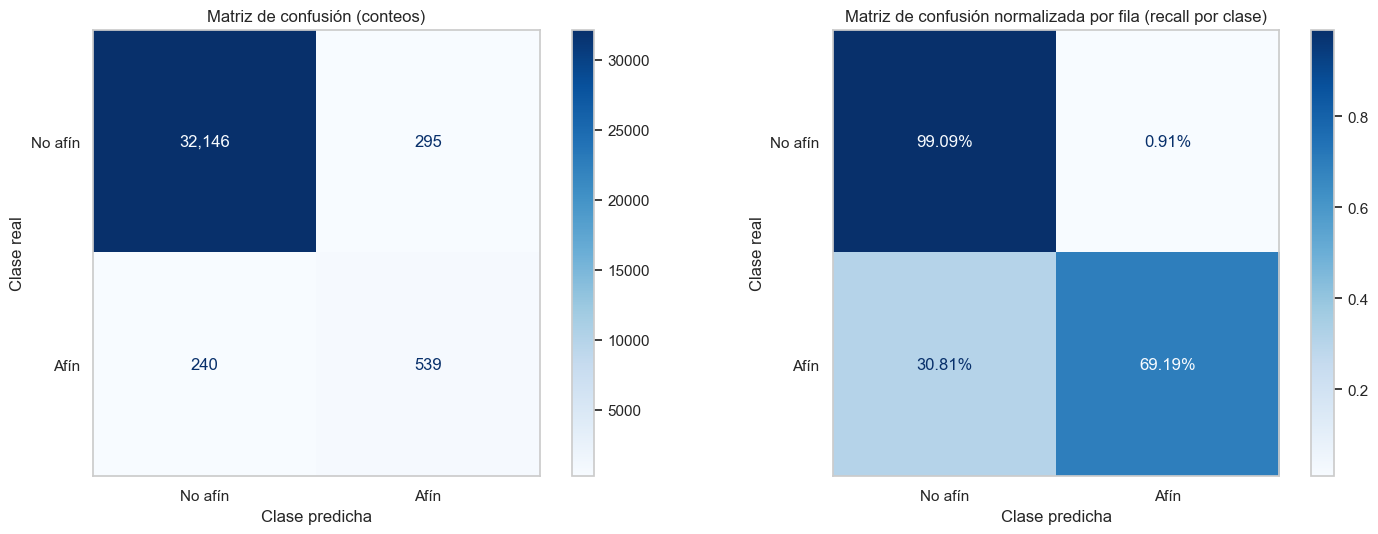

Verdaderos negativos (VN): 32,146 | Falsos positivos (FP): 295
Falsos negativos (FN):     240 | Verdaderos positivos (VP): 539


In [18]:
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(cm, display_labels=['No afín', 'Afín']).plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('Matriz de confusión (conteos)')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize='true'), display_labels=['No afín', 'Afín']).plot(
    ax=axes[1], cmap='Blues', values_format='.2%')
axes[1].set_title('Matriz de confusión normalizada por fila (recall por clase)')
for ax in axes:
    ax.grid(False)
    ax.set(xlabel='Clase predicha', ylabel='Clase real')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos (VN): {tn:,} | Falsos positivos (FP): {fp:,}')
print(f'Falsos negativos (FN):     {fn:,} | Verdaderos positivos (VP): {tp:,}')

### 10.2 Curvas Precision-Recall y ROC

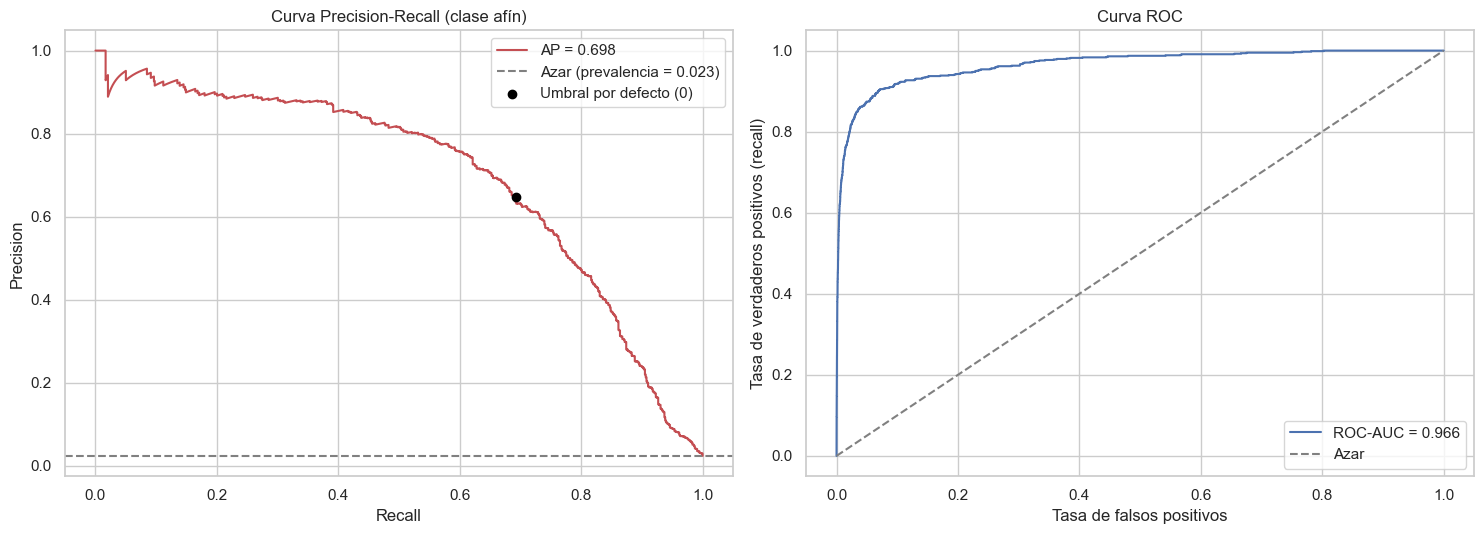

In [19]:
precision_c, recall_c, umbrales_pr = precision_recall_curve(y_test, puntaje_test)
fpr, tpr, _ = roc_curve(y_test, puntaje_test)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot(recall_c, precision_c, color='#C44E52', label=f'AP = {average_precision_score(y_test, puntaje_test):.3f}')
axes[0].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Azar (prevalencia = {y_test.mean():.3f})')
axes[0].scatter(recall_score(y_test, y_pred), precision_score(y_test, y_pred), color='black', zorder=5, label='Umbral por defecto (0)')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Curva Precision-Recall (clase afín)')
axes[0].legend()
axes[1].plot(fpr, tpr, color='#4C72B0', label=f'ROC-AUC = {roc_auc_score(y_test, puntaje_test):.3f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Azar')
axes[1].set(xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos (recall)', title='Curva ROC')
axes[1].legend()
plt.tight_layout()
plt.show()

### 10.3 Ajuste del umbral de decisión
La SVM clasifica como afín cuando `decision_function > 0`. Ese umbral se puede mover según lo que necesite SEIA. Para no hacer trampa con la prueba, el umbral se elige con las **predicciones de validación cruzada sobre el entrenamiento** (`cross_val_predict`) y solo después se aplica a la prueba.

In [20]:
puntaje_cv = cross_val_predict(LinearSVC(max_iter=10_000, random_state=SEED, **grid.best_params_),
                               X_train, y_train, cv=cv, method='decision_function', n_jobs=-1)
p_cv, r_cv, u_cv = precision_recall_curve(y_train, puntaje_cv)
f1_cv = 2 * p_cv[:-1] * r_cv[:-1] / np.clip(p_cv[:-1] + r_cv[:-1], 1e-12, None)
umbral_f1 = u_cv[np.argmax(f1_cv)]
umbral_recall80 = u_cv[np.where(r_cv[:-1] >= 0.80)[0].max()]

filas = []
for nombre, umbral in [('Por defecto (0)', 0.0), ('Máximo F1 (elegido en CV)', umbral_f1),
                       ('Recall ≥ 80 % (elegido en CV)', umbral_recall80)]:
    pred_u = (puntaje_test > umbral).astype(int)
    filas.append({'umbral': nombre, 'valor': umbral, 'precision': precision_score(y_test, pred_u),
                  'recall': recall_score(y_test, pred_u), 'f1': f1_score(y_test, pred_u),
                  'accuracy': accuracy_score(y_test, pred_u), 'marcados como afines': int(pred_u.sum())})
tabla_umbrales = pd.DataFrame(filas).set_index('umbral')
tabla_umbrales.round(4)

,valor,precision,recall,f1,accuracy,marcados como afines
umbral,,,,,,
Por defecto (0),0.0000,0.6463,0.6919,0.6683,0.9839,834
Máximo F1 (elegido en CV),0.1099,0.6922,0.6611,0.6763,0.9852,744
Recall ≥ 80 % (elegido en CV),-0.4419,0.4150,0.8306,0.5535,0.9686,1559


### 10.4 ¿Hay sobreajuste? Entrenamiento vs. prueba

In [21]:
y_pred_train = modelo.predict(X_train)
pd.DataFrame({
    'Entrenamiento': [accuracy_score(y_train, y_pred_train), precision_score(y_train, y_pred_train),
                      recall_score(y_train, y_pred_train), f1_score(y_train, y_pred_train)],
    'Validación cruzada': [np.nan, np.nan, np.nan, grid.best_score_],
    'Prueba': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
               recall_score(y_test, y_pred), f1_score(y_test, y_pred)],
}, index=['Accuracy', 'Precision', 'Recall', 'F1']).round(4)

,Entrenamiento,Validación cruzada,Prueba
Accuracy,0.9968,NaN,0.9839
Precision,0.8800,NaN,0.6463
Recall,1.0000,NaN,0.6919
F1,0.9362,0.6605,0.6683


### Resumen de la evaluación en prueba

| Métrica | Valor en prueba |
|---|---|
| Accuracy | ≈ 0,984 |
| Precision (afín) | ≈ 0,65 |
| Recall (afín) | ≈ 0,69 |
| **F1-Score (afín)** | **≈ 0,67** |
| F1 macro / ponderado | ≈ 0,83 / ≈ 0,98 |
| ROC-AUC | ≈ 0,97 |
| Average Precision | ≈ 0,70 (el azar daría ≈ 0,023) |

**Matriz de confusión** (33.220 contratos de prueba, de los cuales 779 son afines):
- **≈ 539 verdaderos positivos**: contratos afines detectados.
- **≈ 295 falsos positivos**: contratos marcados como afines cuya etiqueta dice que no lo son.
- **≈ 240 falsos negativos**: contratos afines que el modelo no detectó.
- **≈ 32.146 verdaderos negativos**.

**Generalización.** El F1 de prueba (≈ 0,67) coincide con el de validación cruzada (≈ 0,66), así que la estimación es confiable y no hubo un "golpe de suerte" con la partición. La brecha frente al entrenamiento (F1 ≈ 0,94) muestra que el modelo memoriza parte de los textos de entrenamiento, pero su rendimiento con textos nuevos es consistente.

**Umbral de decisión.** El umbral elegido por validación cruzada para maximizar el F1 sube levemente el F1 en prueba (≈ 0,68), con más precisión y algo menos de recall. El umbral de **recall ≥ 80 %** encuentra ≈ 83 % de los afines marcando solo ≈ 4,7 % de los contratos. Para un buscador de oportunidades como SEIA puede ser el punto de operación más útil: es mejor revisar algunos candidatos de más que perder una licitación.

## 11. Interpretación del modelo y análisis de errores
### 11.1 Términos con más peso
Los coeficientes de la SVM indican cuánto empuja cada término hacia "afín" (positivo) o hacia "no afín" (negativo).

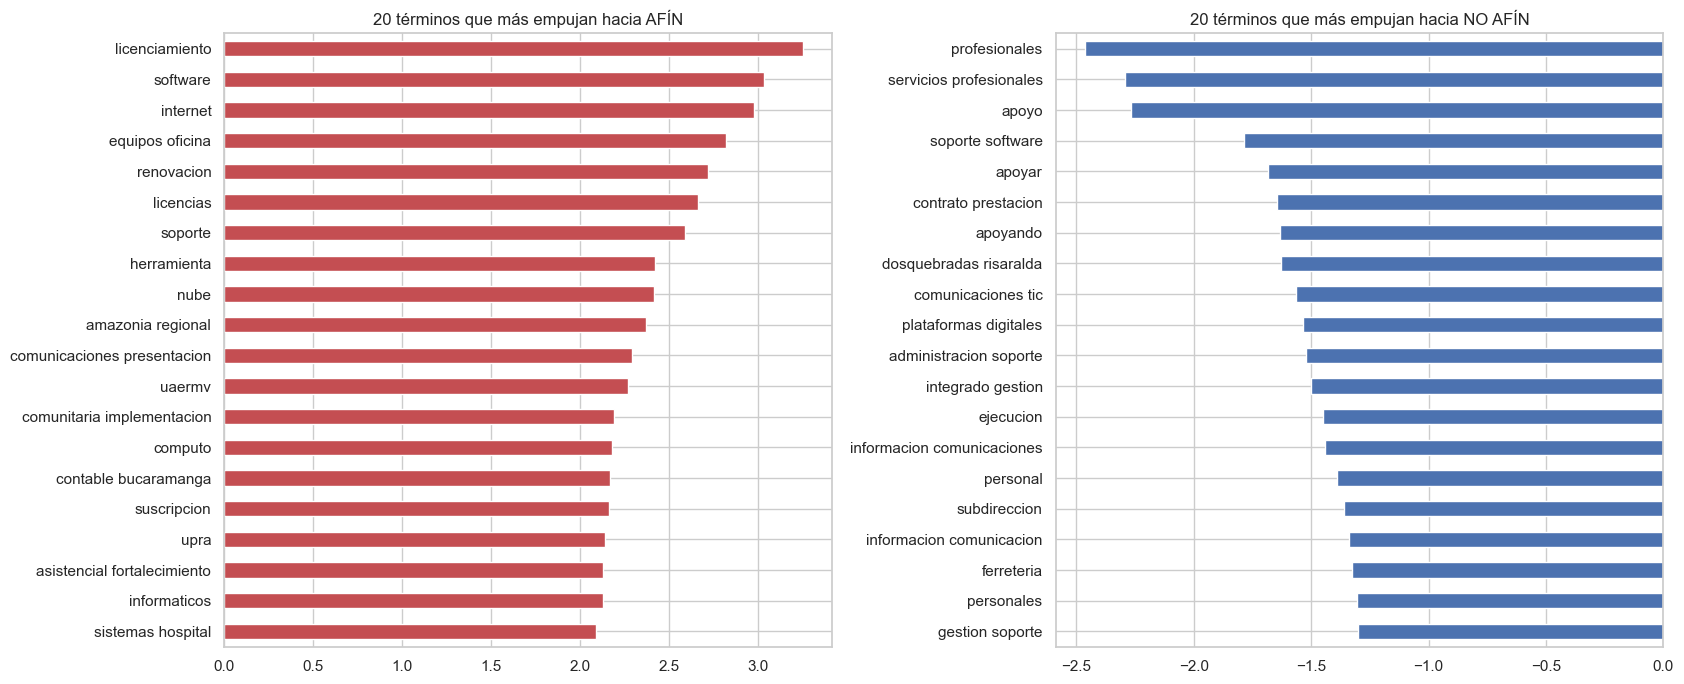

In [22]:
terminos = vectorizador.get_feature_names_out()
coef = modelo.coef_.ravel()
orden = np.argsort(coef)
top_pos = pd.Series(coef[orden[-20:]], index=terminos[orden[-20:]])
top_neg = pd.Series(coef[orden[:20]], index=terminos[orden[:20]])
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
top_pos.plot.barh(ax=axes[0], color='#C44E52')
axes[0].set_title('20 términos que más empujan hacia AFÍN')
top_neg.sort_values(ascending=False).plot.barh(ax=axes[1], color='#4C72B0')
axes[1].set_title('20 términos que más empujan hacia NO AFÍN')
plt.tight_layout()
plt.show()

### 11.2 Análisis de errores

In [23]:
analisis = pd.DataFrame({'texto': df.loc[X_test_txt.index, 'objeto_del_contrato'].str[:170],
                         'codigo_unspsc': df.loc[X_test_txt.index, 'codigo_unspsc'],
                         'real': y_test, 'predicho': y_pred, 'puntaje': puntaje_test}, index=X_test_txt.index)
print('FALSOS POSITIVOS con mayor puntaje (el modelo dice afín, la etiqueta dice no afín):')
display(analisis[(analisis.real == 0) & (analisis.predicho == 1)].nlargest(10, 'puntaje')[['texto', 'codigo_unspsc', 'puntaje']])
print('FALSOS NEGATIVOS con menor puntaje (la etiqueta dice afín, el modelo dice no afín):')
display(analisis[(analisis.real == 1) & (analisis.predicho == 0)].nsmallest(10, 'puntaje')[['texto', 'codigo_unspsc', 'puntaje']])

FALSOS POSITIVOS con mayor puntaje (el modelo dice afín, la etiqueta dice no afín):


,texto,codigo_unspsc,puntaje
127458,Adquirir licencias; soporte y actualización de licencias del software especializado ArcGIS.,81101512,2.353722
86940,CONTRATO DE LICENCIAMIENTO; SOPORTE Y ACTUALIZACION DE SOFTWARE VIGENCIA 2024,80101706,2.268627
17781,PRESTACIÓN DE SERVICIOS DE SOPORTE; LICENCIAS DE ACTUALIZACIÓN Y MANTENIMIENTO (SAM) DE LA PLATAFORMA DE ADMINISTRACIÓN TRIBUTARIA AIRE GESTIÓN E INFRAESTRU...,84101501,1.979299
112821,PRESTACIÓN DE LOS SERVICIOS DE ACTUALIZACIÓN; MANTENIMIENTO; SOPORTE A LA PLATAFORMA GPS-SISFO 7*24; EN LA MODALIDAD SaaS SOFTWARE POR SERVICIOS; PARA EL AÑ...,85101705,1.760792
104327,PRESTAR EL SERVICIO DE COMPUTACION EN LA NUBE DEL SISTEMA DE INFORMACION FINANCIERO Y ADMINISTRATIVO Sinfa® ERP SaaS (Software como Servicio).,80111600,1.728085
65725,SERVICIOS APLICATIVO DE SOFTWARE CUADRO DE TURNOS,93151500,1.713700
30618,DTC108 Contratar el soporte; mantenimiento y actualización de licenciamiento de la planta telefónica AVAYA (IP Office) con la que cuenta TRANSMILENIO.,72103302,1.696490
35084,CONTRATAR SERVICIO SOPORTE; MANTENIMIENTO Y ACTUALIZACION DEL SOFTWARE INTEGRADO DE GESTIÓN EMPRESARIAL SYSCAFE PARA EL MUNICIPIO DE CALARCA,80111600,1.638888
98374,Consultoría individual para realizar soporte y mantenimiento de los aplicativos TuBio; Ocupacol y FILCO; y apoyar los procesos de interoperabilidad e integr...,80101504,1.493808
70712,CONTRATO INTERADMINISTRATIVO PARA LA \nPRESTACIÓN DE SERVICIOS DE MUNICIPIO \nSEGURO; SERVICIOS DE \nTELECOMUNICACIONES; MANTENIMIENTO DE \nCÁMARAS E INSTAL...,83121703,1.483166


FALSOS NEGATIVOS con menor puntaje (la etiqueta dice afín, el modelo dice no afín):


,texto,codigo_unspsc,puntaje
138466,REALIZAR ACCIONES DE APOYO EN LA CLASIFICACIÓN Y ORGANIZACIÓN DE LA DOCUMENTACIÓN GENERADA EN LA EJECUCIÓN DE LOS PROYECTOS DE INVERSIÓN SECTORIAL A CARGO D...,81111500,-1.774190
114275,Prestar los servicios profesionales para apoyar en la elaboración de estudios del sector y de mercado requeridos para la adquisición de bienes y servicios d...,80161506,-1.746793
112087,PRESTACIÓN DE SERVICIOS PROFESIONALES PARA LA SECRETARÍA DE PLANEACIÓN DE APOYO Y ASISTENCIA TÉCNICA EN EL PROCESAMIENTO DE DATOS DEL SISBEN DEL MUNICIPIO D...,81112001,-1.726582
58720,COMPRAVENTA E INSTALACIÓN DE SISTEMAS DE CONTROL DE ASISTENCIA PARA LOS EMPLEADOS DEL PALACIO MUNICIPAL Y UNIDADES ADSCRITAS A LA ADMINISTRACIÓN MUNICIPAL; ...,43201537,-1.711209
76969,PRESTACIÓN DE SERVICIOS PARA APOYAR A LA OFICINA ASESORA DE COMUNICACIONES EN EL MONITOREO DE LA INFORMACIÓN RELACIONADA CON EL SECTOR EDUCACIÓN ASI COMO EN...,43211731,-1.625761
108390,AUNAR ESFUERZOS TÉCNICOS HUMANOS; ADMINISTRATIVOS; LOGÍSTICOS Y FINANCIEROS CON ENTIDAD SIN ÁNIMO DE LUCRO PARA ATENDER LAS ACTIVIDADES DE LA AGENDA DEPORTI...,43232003,-1.616315
33475,PRESTACION DE SERVICIOS DE APOYO A LA GESTION PARA EL MANTENIMIENTO; CONSERVACION Y ADMINISTRACION DE LOS RECURSOS TIC DE LA ALCALDIA DEL MUNICIPIO DE SAN M...,81111702,-1.605307
98603,Prestación de servicios profesionales de estructuración y actualización del\ncálculo actuarial y demás actividades requeridas en relación con pensiones\nde ...,80161506,-1.518231
98094,PRESTACION DE SERVICIOS PROFESIONALES AL INSTITUTO TERMAL\nDE PAIPA PARA GARANTIZAR QUE LA ENTIDAD CUMPLA CON LOS\nREQUERIMIENTOS DEL MODELO INTEGRADO DE PL...,43232804,-1.517134
151056,AUNAR ESFUERZOS TÉCNICOS; ADMINISTRATIVOS Y FINANCIEROS; PARA GARANTIZAR LA LOGISTICA; ORGANIZACIÓN Y EJECUCIÓN DE ACTIVIDADES CULTURALES Y DEPORTIVAS; EN E...,43232400,-1.492128


In [24]:
# ¿Qué códigos UNSPSC tienen los falsos positivos?
fp_codigos = analisis[(analisis.real == 0) & (analisis.predicho == 1)]['codigo_unspsc'].str[:4].value_counts().head(8)
print('Familias UNSPSC más frecuentes entre los falsos positivos:')
print(fp_codigos.to_string())
# Recall por grupo del portafolio
grupo_test = df.loc[X_test_txt.index, 'grupo_portafolio']
recall_grupo = (pd.DataFrame({'grupo': grupo_test, 'acierto': y_pred == 1})[y_test == 1]
                .groupby('grupo')['acierto'].agg(['size', 'mean']).rename(columns={'size': 'afines en prueba', 'mean': 'recall'}))
recall_grupo.round(3)

Familias UNSPSC más frecuentes entre los falsos positivos:
codigo_unspsc
8011    135
8010     22
7215     10
8016     10
8311      7
8110      7
9315      6
8312      6


,afines en prueba,recall
grupo,,
78131804 · Custodia de documentos,5,0.600
80161506 · Archivo de datos,30,0.133
Familia 8111 · Servicios informáticos,445,0.728
Familia 8116 · Entrega de servicios de TI,26,0.308
Segmento 43 · TIC (equipos y software),273,0.733


**Lectura del análisis de errores:**
- **Muchos falsos positivos son en realidad aciertos del modelo.** Los de mayor puntaje son claramente contratos de tecnología: licencias de ArcGIS, licenciamiento de software, ERP en modalidad SaaS, servicios en la nube, soporte de plataformas. La entidad los registró con códigos UNSPSC que no son de TI; el más frecuente es la familia **8011, "servicios de personal"**, que se usa de forma genérica para la prestación de servicios. Aquí **el modelo tiene razón y la etiqueta está mal**. Por eso la precisión medida (≈ 0,65) es una **cota inferior** de la precisión real. Y es justamente el caso de uso de SEIA: encontrar procesos de tecnología escondidos detrás de un código genérico.
- **Varios falsos negativos también son errores de la etiqueta.** Por ejemplo, "estudios del sector y de mercado" y "cálculo actuarial" aparecen codificados como *archivo de datos* (80161506), y "actividades culturales y deportivas" como *software* (segmento 43). El texto no habla de tecnología ni de archivo, así que el modelo los clasifica bien como no afines.
- **Recall por grupo:** es bueno en la parte de tecnología, ≈ 0,73 tanto en el segmento 43 como en la familia 8111. Es bajo en **archivo de datos** (≈ 0,13) y en **entrega de servicios de TI** (≈ 0,31). Esos grupos tienen muy pocos ejemplos (unos 30 y 26 en prueba) y etiquetas muy ruidosas.
- **Los términos con más peso tienen sentido.** Hacia "afín" empujan *licenciamiento, software, internet, licencias, soporte, nube, cómputo, informáticos*. Hacia "no afín" empuja el vocabulario de la prestación de servicios de personal: *profesionales, apoyo, servicios profesionales, personal*. Pero también aparecen **nombres de entidades y lugares** (por ejemplo *uaermv*, *upra*, *amazonia regional*, *dosquebradas risaralda*). El modelo aprendió "atajos" sobre qué entidades suelen comprar tecnología, una forma de sobreajuste a la fuente de datos.

## 12. Uso del modelo en SEIA
El vectorizador y el modelo se guardan juntos con `joblib`, para que `seia-services` u otro proceso de Python pueda puntuar los procesos nuevos que llegan de SECOP II. Debajo se muestra un ejemplo con objetos contractuales escritos a mano, que no forman parte del conjunto de datos, evaluados con dos umbrales:
- **Umbral 0 (balanceado)**: el punto de operación por defecto, con precisión y recall parecidos.
- **Umbral de exploración (recall ≥ 80 %)**: marca más procesos como afines, para que el analista de SEIA revise más candidatos y pierda menos oportunidades.

In [25]:
def predecir_afinidad(textos, umbral=0.0, umbral_exploracion=umbral_recall80):
    limpios = [limpiar_texto(t) for t in textos]
    puntajes = modelo.decision_function(vectorizador.transform(limpios))
    return pd.DataFrame({'objeto': textos, 'puntaje': puntajes.round(3),
                         'umbral 0 (balanceado)': np.where(puntajes > umbral, 'Afín', 'No afín'),
                         f'umbral {umbral_exploracion:.2f} (recall ≥ 80 %)': np.where(puntajes > umbral_exploracion, 'Afín', 'No afín')})


ejemplos = [
    'Implementación de un sistema de gestión de documentos electrónicos de archivo SGDEA para la entidad',
    'Prestación de servicios de digitalización y organización del archivo central conforme a las TRD',
    'Adquisición de licencias de software antivirus y renovación del soporte técnico',
    'Prestación de servicios como auxiliar de enfermería en el hospital municipal',
    'Construcción de placa huella en la vereda El Carmen del municipio',
    'Suministro de refrigerios para las jornadas de capacitación de la secretaría de salud',
]
display(predecir_afinidad(ejemplos))

joblib.dump({'vectorizador': vectorizador, 'modelo': modelo, 'umbral': 0.0,
             'umbral_exploracion': float(umbral_recall80),
             'funcion_limpieza': 'limpiar_texto (ver notebook)'}, 'modelo_afinidad_seia.joblib')
print('Modelo guardado en modelo_afinidad_seia.joblib', f'({os.path.getsize("modelo_afinidad_seia.joblib") / 1e6:.1f} MB)')

,objeto,puntaje,umbral 0 (balanceado),umbral -0.44 (recall ≥ 80 %)
0,Implementación de un sistema de gestión de documentos electrónicos de archivo SGDEA para la entidad,-0.035,No afín,Afín
1,Prestación de servicios de digitalización y organización del archivo central conforme a las TRD,-0.511,No afín,No afín
2,Adquisición de licencias de software antivirus y renovación del soporte técnico,3.401,Afín,Afín
3,Prestación de servicios como auxiliar de enfermería en el hospital municipal,-1.234,No afín,No afín
4,Construcción de placa huella en la vereda El Carmen del municipio,-1.222,No afín,No afín
5,Suministro de refrigerios para las jornadas de capacitación de la secretaría de salud,-1.227,No afín,No afín


Modelo guardado en modelo_afinidad_seia.joblib (7.5 MB)


## 13. Interpretación de los resultados y significado de las métricas

| Métrica | Valor | Qué significa en este problema |
|---|---|---|
| **Accuracy** | ≈ 0,984 | Proporción total de aciertos. **Es engañosa aquí**: responder siempre "no afín" ya da ≈ 0,977. El modelo solo la mejora en unos 0,7 puntos, porque casi todos los aciertos son de la clase mayoritaria |
| **Precision** (afín) | ≈ 0,65 | De cada 100 contratos que el modelo marca como afines, unos 65 lo son según el código UNSPSC. Por el análisis de errores, la precisión real es mayor |
| **Recall** (afín) | ≈ 0,69 | De cada 100 contratos realmente afines, el modelo encuentra unos 69. Los otros 31 se le escapan |
| **F1-Score** (afín) | ≈ 0,67 | Media armónica de precisión y recall. Es la **métrica principal**, porque castiga tanto marcar de más como dejar escapar. Para comparar: Naive Bayes ≈ 0,48 y Dummy = 0 |
| **F1 macro** | ≈ 0,83 | Promedio simple del F1 de ambas clases: le da el mismo peso a la clase minoritaria |
| **F1 ponderado** | ≈ 0,98 | Promedio ponderado por el tamaño de cada clase. Igual que la accuracy, lo domina la clase mayoritaria |
| **Matriz de confusión** | VP ≈ 539 · FP ≈ 295 · FN ≈ 240 · VN ≈ 32.146 | Muestra **dónde** se equivoca el modelo. Los errores están repartidos de forma parecida entre falsos positivos y falsos negativos, señal de un punto de operación equilibrado |
| **ROC-AUC** | ≈ 0,97 | Probabilidad de que un contrato afín elegido al azar reciba un puntaje mayor que uno no afín. Es un **muy buen ordenamiento**: SEIA puede mostrar los procesos ordenados por puntaje |
| **Average Precision** | ≈ 0,70 | Área bajo la curva Precision-Recall. Es unas **30 veces** mejor que el azar (≈ 0,023) |

**Lectura práctica para SEIA.** De 33.220 contratos de prueba, el modelo selecciona unos 830 (2,5 %), y entre ellos están cerca del 69 % de los contratos afines. Con el umbral de exploración, selecciona unos 1.560 (4,7 %) y recupera cerca del 83 %. Un analista que hoy tendría que leer miles de objetos contractuales puede **concentrarse en una lista corta, ordenada por afinidad**.

## 14. Limitaciones y posibles errores
1. **Ruido en la variable objetivo.** El código UNSPSC lo asigna cada entidad y muchas usan códigos genéricos (familia 8011). Eso produce falsos positivos y falsos negativos "aparentes", así que las métricas son una **cota inferior** del rendimiento real. Para medir el rendimiento verdadero haría falta una muestra etiquetada a mano, por ejemplo de 1.000 a 2.000 contratos.
2. **La gestión documental está subrepresentada.** Solo unos 250 contratos tienen los códigos de archivo y custodia documental; cerca del 97 % de los afines son de tecnología. El modelo aprendió sobre todo "tecnología". Los ejemplos de *SGDEA* y *digitalización de archivo* de la sección 12 quedan en la frontera o por debajo del umbral 0. Para cubrir bien esta parte del portafolio hay que agregar ejemplos etiquetados de gestión documental, por ejemplo con palabras clave como "gestión documental", "TRD", "archivo central" o "digitalización", validadas manualmente.
3. **Desbalance de clases (2,3 %).** La precisión es muy sensible a pocos falsos positivos. Se mitigó con `class_weight='balanced'`, estratificación y análisis del umbral, pero no se eliminó.
4. **Atajos (shortcut learning).** Entre los términos más influyentes hay nombres de entidades y municipios. Con entidades nuevas, el modelo puede rendir peor que en la prueba. Se puede mitigar quitando los nombres propios y geográficos, o separando entrenamiento y prueba **por entidad** (`GroupShuffleSplit`).
5. **Casi-duplicados.** Se eliminaron los textos idénticos, pero quedan plantillas casi iguales (mismo texto con otro número o dependencia) en entrenamiento y prueba. Puede quedar algo de optimismo en las métricas.
6. **Texto limitado.** Solo se usa el objeto del contrato, que la API recorta a 500 caracteres. No se usan los pliegos ni los anexos técnicos.
7. **Alcance temporal.** El modelo se entrenó con 2024. El vocabulario de contratación cambia (nuevas tecnologías, normas), así que hay que reentrenarlo periódicamente.
8. **Bolsa de palabras.** TF-IDF no capta el orden de las palabras, los sinónimos ni el contexto. Modelos de *embeddings* o *transformers* en español (por ejemplo BETO) podrían mejorar el recall.
9. **Puntajes no calibrados.** `LinearSVC` entrega distancias al hiperplano, no probabilidades. Si SEIA necesita probabilidades, se puede envolver en `CalibratedClassifierCV`.
10. **Sobreajuste parcial.** El F1 de entrenamiento (≈ 0,94) es mucho mayor que el de prueba (≈ 0,67). El rendimiento en datos nuevos es estable, pero el modelo memoriza parte del entrenamiento.

## 15. Conclusiones
- Se desarrolló un modelo de **aprendizaje supervisado de clasificación binaria** sobre **contratos reales de SECOP II**: se descargaron unos 267.000 y quedaron **≈ 166.000 textos únicos** tras la limpieza. Es la misma fuente de SEIA y la Sección 3 de su documentación ya anticipaba este modelo.
- **Variables:** la entrada es el texto de `objeto_del_contrato`, vectorizado con TF-IDF (unigramas y bigramas, ≈ 187.000 términos). La **variable objetivo** es `afin_portafolio`, derivada de los códigos UNSPSC de tecnología y gestión documental.
- La preparación incluyó la eliminación de etiquetas inválidas, la normalización del texto, la **eliminación de duplicados y de textos con etiquetas contradictorias** (para evitar fuga de datos), y una división **estratificada 80/20** hecha antes de vectorizar.
- **Modelo:** SVM lineal (`LinearSVC`), **no Regresión Lineal**. Se eligió por su eficacia en texto disperso y de alta dimensión, su eficiencia y su interpretabilidad. Le ganó a Naive Bayes y a la línea base en validación cruzada, y se ajustó con `GridSearchCV` (`C = 1`, `class_weight = 'balanced'`).
- **Resultados en prueba:** Accuracy ≈ 0,984, **Precision ≈ 0,65, Recall ≈ 0,69, F1 ≈ 0,67**, ROC-AUC ≈ 0,97, con la matriz de confusión analizada. El F1 coincide con la validación cruzada.
- **La accuracy sola engaña** en problemas desbalanceados. El F1 de la clase de interés, la matriz de confusión y la curva Precision-Recall son las métricas que reflejan el rendimiento real.
- El análisis de errores muestra que **muchos "falsos positivos" son contratos de tecnología mal codificados**. El modelo agrega valor justamente donde el filtro por código UNSPSC de SEIA falla.
- **Siguientes pasos:** etiquetar a mano una muestra para evaluar sin el ruido de los códigos, reforzar los ejemplos de gestión documental y SGDEA, quitar los nombres de entidades para evitar atajos, y exponer el modelo guardado (`modelo_afinidad_seia.joblib`) como un servicio que asigne un **puntaje de afinidad** a cada proceso en `procesos_secop`.